# Import the necessery libraries

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

import numpy as np
import seaborn as sns

# Perceptron class

This perceptron is a simple perceptron with a constant learning rate.

In [46]:
class simple_perceptron :
    def __init__(self, learning_rate: float = 0.1, epochs: int = 1000):
        self.weights = None # the final weights of the perceptron/line after the training.
        self.bias = None # the final bias of the perceptron/line after the training.
        self.lr: float = learning_rate
        self.epochs: int = epochs

    def positive_or_negative_region(self, weighted_sum: np.float64 | np.ndarray):
        return (weighted_sum > 0).astype(int)

    def fit(self, x_train: np.ndarray, y_train: np.ndarray):
        n, m = x_train.shape # 800 rows, 2 input columns.
        a_2d_table_with_n_row_1_column = np.ones(shape=(n, 1))
        x_train = np.hstack((x_train, a_2d_table_with_n_row_1_column)) # both have same number of rows, n for hstack() to work.
        m += 1 # Now its 3 INPUT columns since above we added a column filled with 1 for bias as the last column).
        current_weights_and_bias = np.ones(shape=(m), dtype=np.float64) # Current Line means "current_weights_and_bias".

        for _ in range(self.epochs):
            # i) pick a random input x and its y :
            random_index: int = np.random.randint(low=0, high=n)
            x, y = x_train[random_index], y_train[random_index] # In x, remember again the last column with 1 is for bias.
            # ii) predict for this input in terms of the current line :
            weighted_sum = np.dot(current_weights_and_bias, x) # Output is a np.float64 type.
            y_hat = self.positive_or_negative_region(np.asarray([weighted_sum])) [0]
            # iii) correct rotation and bias the line if misclassified for x, otherwise keep the line as it was :
            current_weights_and_bias = current_weights_and_bias + (y - y_hat) * self.lr * x

        self.weights, self.bias = current_weights_and_bias[:-1], current_weights_and_bias[-1]

    def predict(self, x_test: np.ndarray):
        if len(x_test.shape) == 1:
            print("x_test must be 2D Array")
            return None
        
        weighted_sum = np.dot(x_test, self.weights) + self.bias # (n,2) dot (2) -> (n). If it was the other way, np.dot won't work.
        return self.positive_or_negative_region(weighted_sum)


# Training, testing, drawing the perceptron/line on the graph along input dataset

In [ ]:

# create/import the dataset, split the dataset in the way we want :
X, y = make_classification(n_samples=100, n_features=2, n_informative=1, n_redundant=0,
                            n_classes=2, n_clusters_per_class=1, random_state=41, hypercube=False, class_sep=15)

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

print(type(X), type(y_train))

<class 'numpy.ndarray'> <class 'numpy.ndarray'>


Weights = [1.12322126 0.36468077]
Intercept = 1.2000000000000002
Total wrong predictions = 0


<Axes: >

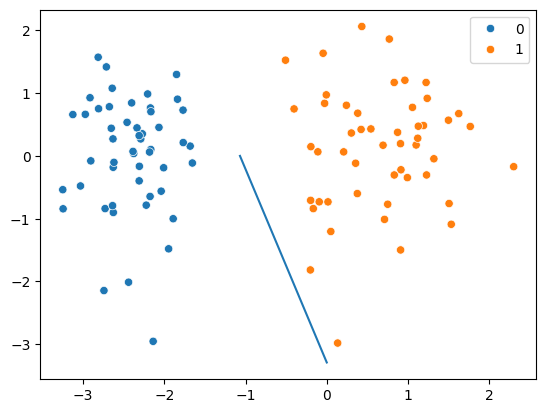

In [ ]:
# fit/train the model and check the error it made by predicting on x_test :
perceptron = simple_perceptron(epochs = 1000)
perceptron.fit(x_train, y_train)

print(f"Weights = {perceptron.weights}")
print(f"Intercept = {perceptron.bias}")

predicted_y_test = perceptron.predict(x_test)
print("Total wrong predictions =", np.abs(y_test - predicted_y_test).sum())


sns.scatterplot(x = X[:, 0], y = X[:, 1], hue=y)

A, B, b = perceptron.weights[0], perceptron.weights[1], perceptron.bias
x_intercept, y_intercept = [-b/A, 0], [0, -b/B]
sns.lineplot(x = x_intercept, y = y_intercept)

But as you can see the height of the perceptron/line is short on the Y axis. So the line needs to extend all the way up to maximum y axis value. To extend the line to maximum y axis, we need to know how steep the line is, which direction it goes i.e. how much changes happen in y axis when x changes. And this is slope. Remember y = mx + b which is also a line equation and another form is Ax + By + C = 0. Now you know y = [y.min(), y.max()]. Just find x. (below)

[-2.98092432  2.0615874 ]


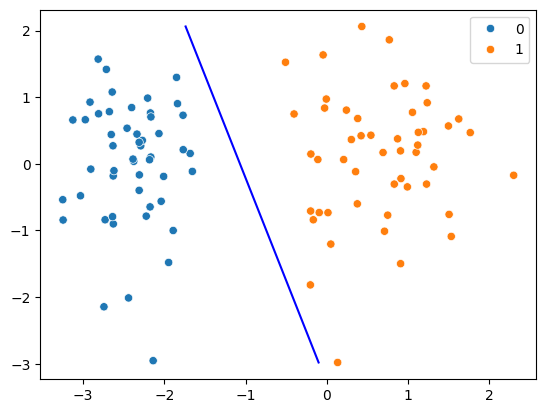

In [ ]:
# Draw the whole perceptron line on the whole y axis :
m = -perceptron.weights[0] / perceptron.weights[1] # -A/B
b = -perceptron.bias / perceptron.weights[1] # -bias/B

y_axis_values = np.asarray([X[:, 1].min(), X[:, 1].max()]) # X[:, 1] = The whole 2nd column.
x_axis_values = (y_axis_values - b) / m

sns.scatterplot(x = X[:, 0], y = X[:, 1], hue=y)
sns.lineplot(x = x_axis_values, y = y_axis_values, color="blue")

print(y_axis_values)